# P38 — AI-Based Personalized Learning and Student Performance Predictor

**Unified submission notebook**  
**Development notebooks:** `01_EDA_and_Preprocessing.ipynb`, `02_Model_Training_and_Evaluation.ipynb`, and `03_Personalized_Recommendations.ipynb`

This notebook combines the essential end-to-end workflow into one place for submission and demonstration. The three modular notebooks remain the preferred files for day-to-day development and revision.

**Project goal:** Predict an engineered student mastery category (Low, Medium, or High) from five categorical student-profile features, then provide a simple practice recommendation. A separate post-exam rule identifies the lowest-scoring subject from actual scores.

> **Important limitation:** This dataset has exam scores but no question-level difficulty labels or topic-level learning history. The model predicts a broad student performance category; it does not learn the difficulty of individual questions.

## Section 1 — Imports and Project Setup

We import the libraries needed for data analysis, visualization, preprocessing, model training, evaluation, and saving artifacts. A fixed seed helps make the train/validation/test split and model training more reproducible.

In [1]:
import os
import random
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import tensorflow as tf
from tensorflow import keras

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    precision_recall_fscore_support,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import OneHotEncoder
from sklearn.utils.class_weight import compute_class_weight

SEED = 42
os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully.")
print(f"scikit-learn version: {sklearn.__version__}")
print(f"TensorFlow version: {tf.__version__}")

I0000 00:00:1793259241.949012   38958 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793259241.992024   38958 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793259243.504821   38958 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


Libraries imported successfully.
scikit-learn version: 1.9.1
TensorFlow version: 2.21.0


### 1.1 Locate the Project and Load the Dataset

This cell supports running the notebook with the working directory set either to the project root or to its `notebooks/` folder. The CSV is expected at `data/StudentsPerformance.csv`.

In [2]:
CURRENT_DIR = Path.cwd()

if (CURRENT_DIR / "data" / "StudentsPerformance.csv").exists():
    PROJECT_ROOT = CURRENT_DIR
elif (CURRENT_DIR.parent / "data" / "StudentsPerformance.csv").exists():
    PROJECT_ROOT = CURRENT_DIR.parent
else:
    raise FileNotFoundError(
        "Could not find data/StudentsPerformance.csv. "
        f"Current working directory: {CURRENT_DIR.resolve()}. "
        "Place the dataset in the project's data/ folder."
    )

DATA_PATH = PROJECT_ROOT / "data" / "StudentsPerformance.csv"
MODELS_DIR = PROJECT_ROOT / "models"
REPORTS_DIR = PROJECT_ROOT / "reports"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

df = pd.read_csv(DATA_PATH)

print(f"Project root: {PROJECT_ROOT.resolve()}")
print(f"Dataset path: {DATA_PATH.resolve()}")
print(f"Dataset shape: {df.shape}")
display(df.head())

Project root: /home/waterball/Desktop/AI-Student-Performance-Predictor
Dataset path: /home/waterball/Desktop/AI-Student-Performance-Predictor/data/StudentsPerformance.csv
Dataset shape: (1000, 8)


,gender,race/ethnicity,parental level of education,lunch,test preparation course,math score,reading score,writing score
0,female,group B,bachelor's degree,standard,none,72,72,74
1,female,group C,some college,standard,completed,69,90,88
2,female,group B,master's degree,standard,none,90,95,93
3,male,group A,associate's degree,free/reduced,none,47,57,44
4,male,group C,some college,standard,none,76,78,75


## Section 2 — Dataset Validation

Before analysing or modelling the data, check its structure, missing values, duplicate rows, categorical values, and score ranges. These checks help catch data-quality problems early.

### 2.1 Check Columns, Types, Missing Values, and Duplicates

In [3]:
EXPECTED_COLUMNS = [
    "gender",
    "race/ethnicity",
    "parental level of education",
    "lunch",
    "test preparation course",
    "math score",
    "reading score",
    "writing score",
]
CATEGORICAL_FEATURES = EXPECTED_COLUMNS[:5]
SCORE_COLUMNS = EXPECTED_COLUMNS[5:]

missing_columns = [column for column in EXPECTED_COLUMNS if column not in df.columns]
if missing_columns:
    raise ValueError(f"Dataset is missing expected columns: {missing_columns}")

print("Column information:")
df.info()
print("\nMissing values per column:")
display(df.isna().sum().to_frame("Missing values"))
print(f"\nExact duplicate rows: {df.duplicated().sum()}")
print("\nSummary statistics for exam scores:")
display(df[SCORE_COLUMNS].describe())

scores_in_range = df[SCORE_COLUMNS].apply(lambda column: column.between(0, 100).all())
print("\nAll scores are within 0–100:")
display(scores_in_range.to_frame("Valid score range"))

print("\nUnique values in categorical features:")
for column in CATEGORICAL_FEATURES:
    print(f"\n{column}: {df[column].nunique()} categories")
    display(df[column].value_counts().to_frame("Count"))

Column information:
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 8 columns):
 #   Column                       Non-Null Count  Dtype
---  ------                       --------------  -----
 0   gender                       1000 non-null   str  
 1   race/ethnicity               1000 non-null   str  
 2   parental level of education  1000 non-null   str  
 3   lunch                        1000 non-null   str  
 4   test preparation course      1000 non-null   str  
 5   math score                   1000 non-null   int64
 6   reading score                1000 non-null   int64
 7   writing score                1000 non-null   int64
dtypes: int64(3), str(5)
memory usage: 62.6 KB

Missing values per column:


,Missing values
gender,0
race/ethnicity,0
parental level of education,0
lunch,0
test preparation course,0
math score,0
reading score,0
writing score,0



Exact duplicate rows: 0

Summary statistics for exam scores:


,math score,reading score,writing score
count,1000.00000,1000.000000,1000.000000
mean,66.08900,69.169000,68.054000
std,15.16308,14.600192,15.195657
min,0.00000,17.000000,10.000000
25%,57.00000,59.000000,57.750000
50%,66.00000,70.000000,69.000000
75%,77.00000,79.000000,79.000000
max,100.00000,100.000000,100.000000



All scores are within 0–100:


...

,Count
parental level of education,
some college,226
associate's degree,222
high school,196
some high school,179
bachelor's degree,118
master's degree,59



lunch: 2 categories


,Count
lunch,
standard,645
free/reduced,355



test preparation course: 2 categories


,Count
test preparation course,
none,642
completed,358


### Key concepts

- **Missing values:** entries that have no recorded value.
- **Duplicate rows:** records whose values match across every column.
- **Categorical features:** fields that represent groups or labels rather than measured numerical amounts.
- **Validation checks:** confirm the input matches our expectations before modelling.

## Section 3 — Exploratory Data Analysis (EDA)

EDA uses tables and visualizations to understand the score distributions and the relationships between variables. These plots describe patterns in this dataset; they do not establish causal relationships.

### 3.1 Distribution of Exam Scores

Histograms show how frequently scores occur across score ranges. The KDE curve is a smoothed estimate of the distribution.

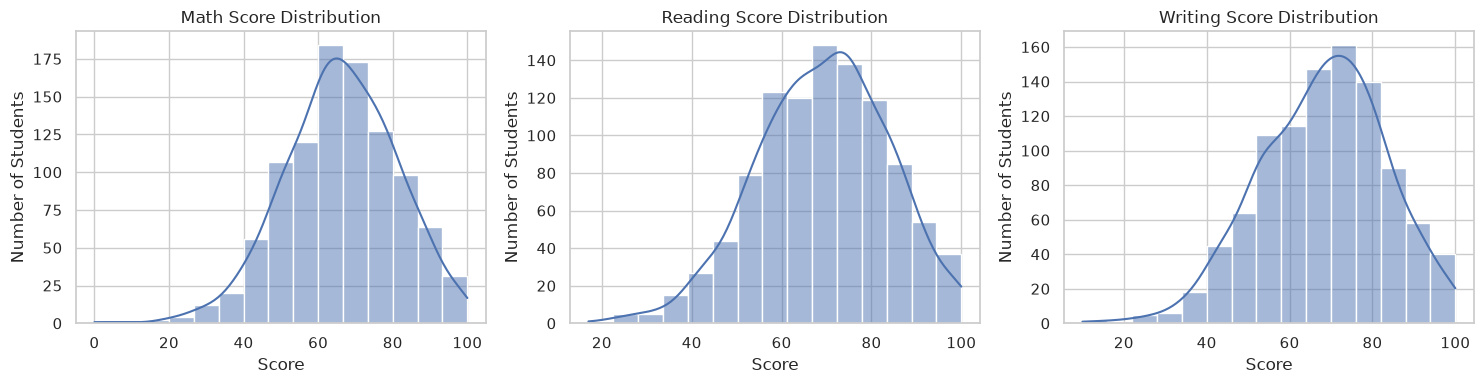

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, column in zip(axes, SCORE_COLUMNS):
    sns.histplot(df[column], bins=15, kde=True, ax=ax)
    ax.set_title(f"{column.title()} Distribution")
    ax.set_xlabel("Score")
    ax.set_ylabel("Number of Students")
plt.tight_layout()
plt.show()

### 3.2 Correlation Between Exam Scores

Correlation measures the direction and strength of a linear relationship between two numerical variables. A high positive correlation does not mean one score causes another.

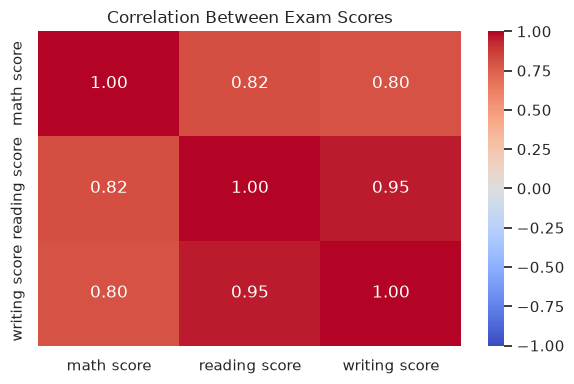

,math score,reading score,writing score
math score,1.000,0.818,0.803
reading score,0.818,1.000,0.955
writing score,0.803,0.955,1.000


In [5]:
score_correlation = df[SCORE_COLUMNS].corr()
plt.figure(figsize=(6, 4))
sns.heatmap(score_correlation, annot=True, cmap="coolwarm", vmin=-1, vmax=1, fmt=".2f")
plt.title("Correlation Between Exam Scores")
plt.tight_layout()
plt.show()
display(score_correlation.round(3))

### 3.3 Compare Average Scores Across Student Groups

A boxplot displays the median, spread, and potential outliers in a numerical variable across categories. Here, average score is used only for descriptive analysis and later for creating the target; it is **not** used as a model input.

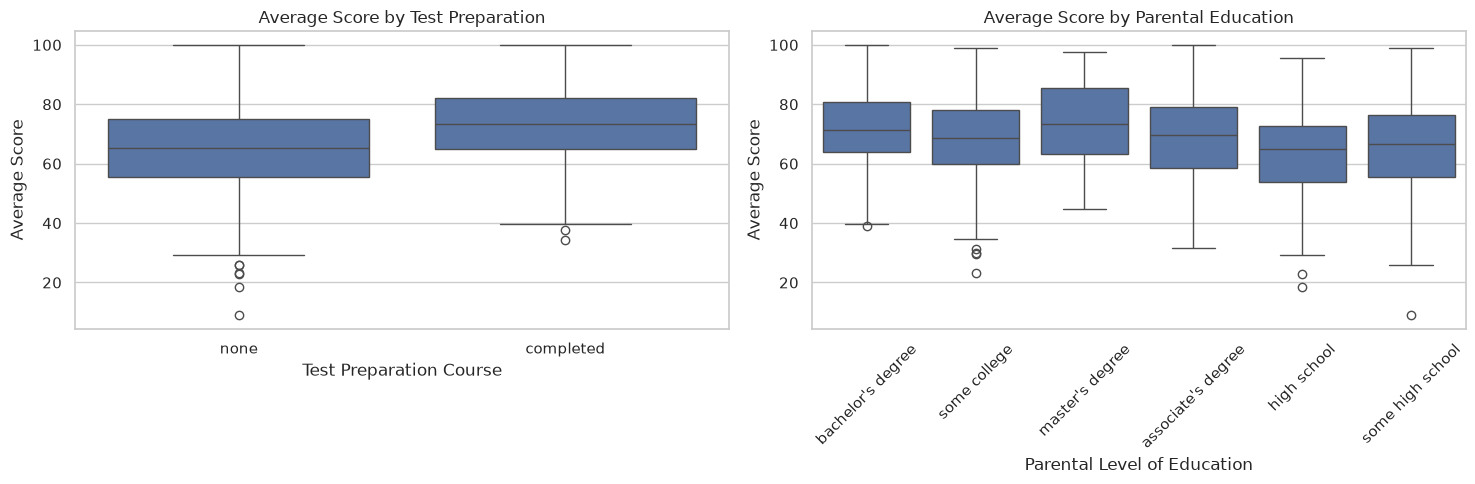

In [6]:
df["average_score"] = df[SCORE_COLUMNS].mean(axis=1)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
sns.boxplot(data=df, x="test preparation course", y="average_score", ax=axes[0])
axes[0].set_title("Average Score by Test Preparation")
axes[0].set_xlabel("Test Preparation Course")
axes[0].set_ylabel("Average Score")
sns.boxplot(data=df, x="parental level of education", y="average_score", ax=axes[1])
axes[1].set_title("Average Score by Parental Education")
axes[1].set_xlabel("Parental Level of Education")
axes[1].set_ylabel("Average Score")
axes[1].tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

**EDA reminder:** group differences and correlations are observational associations. They do not prove that a demographic or preparation feature causes higher or lower performance.

## Section 4 — Target Engineering: Create Mastery Categories

The dataset does not provide an official mastery label. We create one from each student's average score using the thresholds agreed for this project:

- **Low:** average below 50
- **Medium:** average from 50 to below 75
- **High:** average 75 or above

These are engineered labels, not original dataset labels. We retain the thresholds even if the class counts are uneven.

,Number of Students,Percentage
mastery_level,,
Low,103,10.3
Medium,573,57.3
High,324,32.4


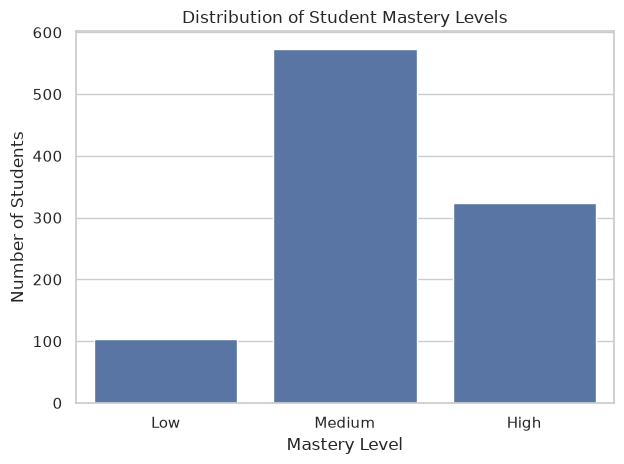

In [7]:
CLASS_NAMES = ["Low", "Medium", "High"]
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
INDEX_TO_CLASS = {index: name for name, index in CLASS_TO_INDEX.items()}

df["mastery_level"] = pd.cut(
    df["average_score"],
    bins=[-np.inf, 50, 75, np.inf],
    labels=CLASS_NAMES,
    right=False,
)
if df["mastery_level"].isna().any():
    raise ValueError("Some mastery labels are missing. Check the score columns.")

mastery_counts = df["mastery_level"].value_counts().reindex(CLASS_NAMES, fill_value=0)
mastery_summary = pd.DataFrame({
    "Number of Students": mastery_counts,
    "Percentage": (mastery_counts / len(df) * 100).round(2),
})
display(mastery_summary)

sns.countplot(data=df, x="mastery_level", order=CLASS_NAMES)
plt.title("Distribution of Student Mastery Levels")
plt.xlabel("Mastery Level")
plt.ylabel("Number of Students")
plt.tight_layout()
plt.show()

### What to remember

- **Target engineering:** creating labels from existing columns using explicit rules.
- **Class imbalance:** target classes have different numbers of examples.
- Our model inputs are the five categorical features. Exam scores and `average_score` are excluded because they define the target; using them as inputs would cause target leakage.

## Section 5 — Split Data into Training, Validation, and Test Sets

We use a **60% training / 20% validation / 20% test** split. Stratification keeps class proportions similar across the splits as far as possible.

- **Training set:** fits preprocessing and models.
- **Validation set:** compares models and supports model selection.
- **Test set:** provides a held-out performance evaluation.

In [8]:
X = df[CATEGORICAL_FEATURES].copy()
y = df["mastery_level"].astype(str).copy()

# Reserve 20% for the final test set.
X_train_val, X_test, y_train_val, y_test = train_test_split(
    X, y, test_size=0.20, random_state=SEED, stratify=y
)
# Reserve 25% of the remaining 80% for validation (20% overall).
X_train, X_val, y_train, y_val = train_test_split(
    X_train_val, y_train_val, test_size=0.25,
    random_state=SEED, stratify=y_train_val
)

split_summary = pd.DataFrame({
    "Rows": [len(X_train), len(X_val), len(X_test)],
    "Percentage of dataset": [100 * len(X_train) / len(df), 100 * len(X_val) / len(df), 100 * len(X_test) / len(df)],
}, index=["Training", "Validation", "Test"])
display(split_summary.round(1))
print("\nTarget proportions by split:")
for split_name, labels in [("Training", y_train), ("Validation", y_val), ("Test", y_test)]:
    print(f"\n{split_name}")
    display((labels.value_counts(normalize=True).reindex(CLASS_NAMES, fill_value=0) * 100).round(1).to_frame("Percentage"))

,Rows,Percentage of dataset
Training,600,60.0
Validation,200,20.0
Test,200,20.0



Target proportions by split:

Training


,Percentage
mastery_level,
Low,10.3
Medium,57.3
High,32.3



Validation


,Percentage
mastery_level,
Low,10.5
Medium,57.0
High,32.5



Test


,Percentage
mastery_level,
Low,10.0
Medium,57.5
High,32.5


## Section 6 — Encode the Categorical Features

Most machine-learning algorithms need numerical inputs. One-hot encoding represents each category as a 0/1 indicator column.

We fit the encoder on **training data only**. Validation and test data are transformed with that same fitted encoder to avoid leaking information from held-out examples into preprocessing.

In [9]:
preprocessor = ColumnTransformer(
    transformers=[
        ("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), CATEGORICAL_FEATURES)
    ],
    remainder="drop",
    verbose_feature_names_out=False,
)

X_train_encoded = preprocessor.fit_transform(X_train)
X_val_encoded = preprocessor.transform(X_val)
X_test_encoded = preprocessor.transform(X_test)
feature_names = preprocessor.get_feature_names_out()

y_train_encoded = y_train.map(CLASS_TO_INDEX).to_numpy(dtype=np.int32)
y_val_encoded = y_val.map(CLASS_TO_INDEX).to_numpy(dtype=np.int32)
y_test_encoded = y_test.map(CLASS_TO_INDEX).to_numpy(dtype=np.int32)

print("Encoded shapes:")
print("Training:", X_train_encoded.shape)
print("Validation:", X_val_encoded.shape)
print("Test:", X_test_encoded.shape)
print("Number of encoded features:", len(feature_names))
display(pd.DataFrame(X_train_encoded, columns=feature_names).head())

Encoded shapes:
Training: (600, 17)
Validation: (200, 17)
Test: (200, 17)
Number of encoded features: 17


,gender_female,gender_male,race/ethnicity_group A,race/ethnicity_group B,race/ethnicity_group C,race/ethnicity_group D,race/ethnicity_group E,parental level of education_associate's degree,parental level of education_bachelor's degree,parental level of education_high school,parental level of education_master's degree,parental level of education_some college,parental level of education_some high school,lunch_free/reduced,lunch_standard,test preparation course_completed,test preparation course_none
0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
1,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
2,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0
3,1.0,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0
4,1.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,1.0


## Section 7 — Train Baseline Models

Before using deep learning, we train two baselines:

1. **Dummy Classifier:** predicts the most frequent training category and ignores the input features.
2. **Logistic Regression:** a conventional classification model that estimates class probabilities.

We compare the models on validation data, before looking at the held-out test evaluation.

In [10]:
def calculate_metrics(y_true, y_pred):
    """Return accuracy and macro-F1 for a classification prediction."""
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Macro-F1": f1_score(y_true, y_pred, labels=CLASS_NAMES, average="macro", zero_division=0),
    }


dummy_model = DummyClassifier(strategy="most_frequent")
dummy_model.fit(X_train_encoded, y_train)

logistic_model = LogisticRegression(max_iter=2000, random_state=SEED)
logistic_model.fit(X_train_encoded, y_train)

baseline_validation_predictions = {
    "Dummy Classifier": dummy_model.predict(X_val_encoded),
    "Logistic Regression": logistic_model.predict(X_val_encoded),
}
baseline_validation_results = pd.DataFrame([
    {"Model": name, **calculate_metrics(y_val, predictions)}
    for name, predictions in baseline_validation_predictions.items()
]).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
display(baseline_validation_results.round(3))

,Model,Accuracy,Macro-F1
0,Logistic Regression,0.585,0.439
1,Dummy Classifier,0.570,0.242


### Metric reminder

- **Accuracy:** proportion of predictions that are correct overall.
- **Macro-F1:** computes an F1-score for each class and averages the three scores equally. It is helpful when class sizes differ.

## Section 8 — Train the Neural Network

The project includes a small multilayer perceptron (MLP) using Keras. It contains two hidden Dense layers, dropout, and a three-class softmax output.

- **ReLU:** activation function in the hidden layers.
- **Softmax:** converts output scores into class probabilities.
- **Sparse categorical cross-entropy:** loss function for integer-coded multi-class labels.
- **Early stopping:** stops training when validation loss stops improving and restores the best weights.

In [11]:
neural_model = keras.Sequential([
    keras.layers.Input(shape=(X_train_encoded.shape[1],)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(len(CLASS_NAMES), activation="softmax"),
])

neural_model.compile(
    optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"],
)
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)
history = neural_model.fit(
    X_train_encoded,
    y_train_encoded,
    validation_data=(X_val_encoded, y_val_encoded),
    epochs=100,
    batch_size=32,
    callbacks=[early_stopping],
    verbose=1,
)
print(f"Training stopped after {len(history.history['loss'])} epoch(s).")

Epoch 1/100


E0000 00:00:1793259309.227877   38958 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.5667 - loss: 0.9846 - val_accuracy: 0.5700 - val_loss: 0.9317
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.5733 - loss: 0.9192 - val_accuracy: 0.5700 - val_loss: 0.9113
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5717 - loss: 0.8930 - val_accuracy: 0.5700 - val_loss: 0.8964
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5767 - loss: 0.8793 - val_accuracy: 0.5700 - val_loss: 0.8852
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5767 - loss: 0.8631 - val_accuracy: 0.5550 - val_loss: 0.8775
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5917 - loss: 0.8476 - val_accuracy: 0.5750 - val_loss: 0.8725
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.5933 - loss: 0.8292 - val_accuracy: 0.5650 - val_loss: 0.8716
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.6067 - loss: 0.8248 - val_accuracy: 0.5700 - val_loss: 0.8

### 8.1 Inspect the Learning Curves

Training curves help us see whether the model learns the training examples and whether validation performance diverges from training performance.

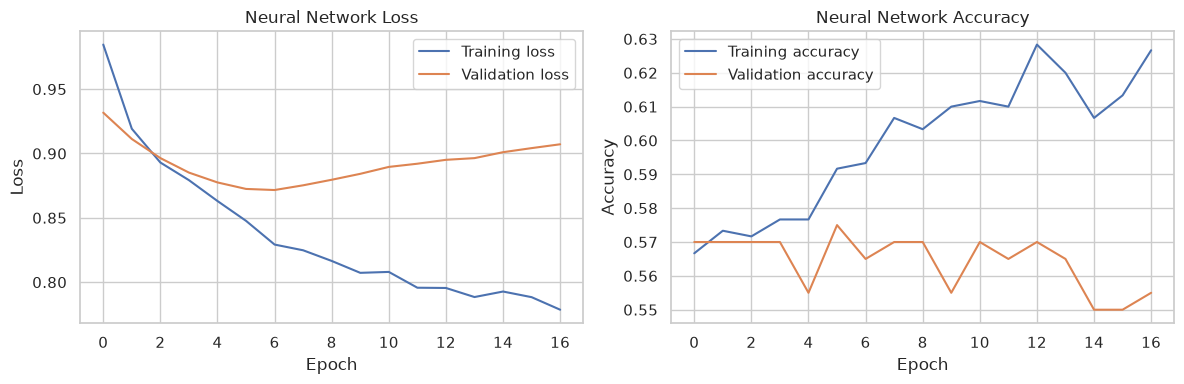

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history.history["loss"], label="Training loss")
axes[0].plot(history.history["val_loss"], label="Validation loss")
axes[0].set_title("Neural Network Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[1].plot(history.history["accuracy"], label="Training accuracy")
axes[1].plot(history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Neural Network Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
fig.savefig(REPORTS_DIR / "training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 9 — Class-Weighting Experiment

The initial models struggled to recognize the Low category. In this experiment, we give larger training weights to less frequent classes and compare the weighted models using **validation data**.

Class weighting may improve recall for the minority class, but it can also increase false positives or reduce overall performance. We keep the original models and artifacts unchanged.

### 9.1 Calculate Weights from Training Labels

The weights are calculated from the training labels only. No validation or test labels are used to calculate them.

In [13]:
class_weight_values = compute_class_weight(
    class_weight="balanced",
    classes=np.array(CLASS_NAMES),
    y=y_train.to_numpy(),
)
class_weights_by_name = {
    class_name: float(weight)
    for class_name, weight in zip(CLASS_NAMES, class_weight_values)
}
keras_class_weights = {
    CLASS_TO_INDEX[class_name]: weight
    for class_name, weight in class_weights_by_name.items()
}

weight_summary = pd.DataFrame({
    "Training Examples": y_train.value_counts().reindex(CLASS_NAMES),
    "Class Weight": pd.Series(class_weights_by_name),
})
display(weight_summary)

weighted_logistic_model = LogisticRegression(
    max_iter=2000, random_state=SEED, class_weight="balanced"
)
weighted_logistic_model.fit(X_train_encoded, y_train)

keras.utils.set_random_seed(SEED + 1)
weighted_neural_model = keras.Sequential([
    keras.layers.Input(shape=(X_train_encoded.shape[1],)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(len(CLASS_NAMES), activation="softmax"),
])
weighted_neural_model.compile(
    optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"]
)
weighted_early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=10, restore_best_weights=True
)
weighted_history = weighted_neural_model.fit(
    X_train_encoded,
    y_train_encoded,
    validation_data=(X_val_encoded, y_val_encoded),
    class_weight=keras_class_weights,
    epochs=100,
    batch_size=32,
    callbacks=[weighted_early_stopping],
    verbose=1,
)
print(f"Weighted neural network training stopped after {len(weighted_history.history['loss'])} epoch(s).")

,Training Examples,Class Weight
Low,62,3.225806
Medium,344,0.581395
High,194,1.030928


Epoch 1/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - accuracy: 0.2033 - loss: 1.1104 - val_accuracy: 0.3150 - val_loss: 1.1132
Epoch 2/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3500 - loss: 1.0671 - val_accuracy: 0.4250 - val_loss: 1.0858
Epoch 3/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.3867 - loss: 1.0394 - val_accuracy: 0.4050 - val_loss: 1.0886
Epoch 4/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4350 - loss: 1.0021 - val_accuracy: 0.3750 - val_loss: 1.0792
Epoch 5/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - accuracy: 0.4200 - loss: 0.9865 - val_accuracy: 0.4100 - val_loss: 1.0736
Epoch 6/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4550 - loss: 0.9666 - val_accuracy: 0.3900 - val_loss: 1.0781
Epoch 7/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4550 - loss: 0.9476 - val_accuracy: 0.3900 - val_loss: 1.0707
Epoch 8/100
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - accuracy: 0.4533 - loss: 0.9366 - val_accuracy: 0.4050 - v

### 9.2 Compare All Five Models on the Validation Set

We use validation macro-F1 to compare class-wise performance and inspect Low-class recall before choosing a model. We do not use test results to choose the weighted model.

In [14]:
def decode_neural_predictions(model, encoded_features):
    probabilities = model.predict(encoded_features, verbose=0)
    indices = np.argmax(probabilities, axis=1)
    return np.array([INDEX_TO_CLASS[int(index)] for index in indices])


validation_predictions_experiment = {
    "Dummy Classifier": dummy_model.predict(X_val_encoded),
    "Logistic Regression": logistic_model.predict(X_val_encoded),
    "Neural Network": decode_neural_predictions(neural_model, X_val_encoded),
    "Logistic Regression (Class Weighted)": weighted_logistic_model.predict(X_val_encoded),
    "Neural Network (Class Weighted)": decode_neural_predictions(weighted_neural_model, X_val_encoded),
}

validation_comparison = pd.DataFrame([
    {"Model": name, **calculate_metrics(y_val, predictions)}
    for name, predictions in validation_predictions_experiment.items()
]).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
display(validation_comparison.round(3))

validation_comparison.to_csv(REPORTS_DIR / "validation_class_weighting_comparison.csv", index=False)

,Model,Accuracy,Macro-F1
0,Logistic Regression,0.585,0.439
1,Neural Network (Class Weighted),0.405,0.389
2,Logistic Regression (Class Weighted),0.380,0.362
3,Neural Network,0.565,0.331
4,Dummy Classifier,0.570,0.242


### 9.3 Inspect Per-Class Validation Performance

Per-class recall shows how many actual students in a category were correctly identified. This is especially important for the smaller Low class.

In [15]:
detailed_validation_rows = []
for model_name, predictions in validation_predictions_experiment.items():
    precision, recall, f1, support = precision_recall_fscore_support(
        y_val, predictions, labels=CLASS_NAMES, zero_division=0
    )
    row = {
        "Model": model_name,
        "Accuracy": accuracy_score(y_val, predictions),
        "Macro-F1": f1_score(y_val, predictions, labels=CLASS_NAMES, average="macro", zero_division=0),
    }
    for index, class_name in enumerate(CLASS_NAMES):
        row[f"{class_name} Precision"] = precision[index]
        row[f"{class_name} Recall"] = recall[index]
        row[f"{class_name} F1"] = f1[index]
    detailed_validation_rows.append(row)

detailed_validation_comparison = pd.DataFrame(detailed_validation_rows)
display(detailed_validation_comparison.sort_values("Macro-F1", ascending=False).round(3))

,Model,Accuracy,Macro-F1,Low Precision,Low Recall,Low F1,Medium Precision,Medium Recall,Medium F1,High Precision,High Recall,High F1
1,Logistic Regression,0.585,0.439,0.750,0.143,0.240,0.599,0.825,0.694,0.513,0.308,0.385
4,Neural Network (Class Weighted),0.405,0.389,0.207,0.571,0.304,0.596,0.272,0.373,0.422,0.585,0.490
3,Logistic Regression (Class Weighted),0.380,0.362,0.157,0.524,0.242,0.595,0.219,0.321,0.455,0.615,0.523
2,Neural Network,0.565,0.331,0.000,0.000,0.000,0.579,0.868,0.695,0.483,0.215,0.298
0,Dummy Classifier,0.570,0.242,0.000,0.000,0.000,0.570,1.000,0.726,0.000,0.000,0.000


### 9.4 Weighted Neural Network Learning Curves

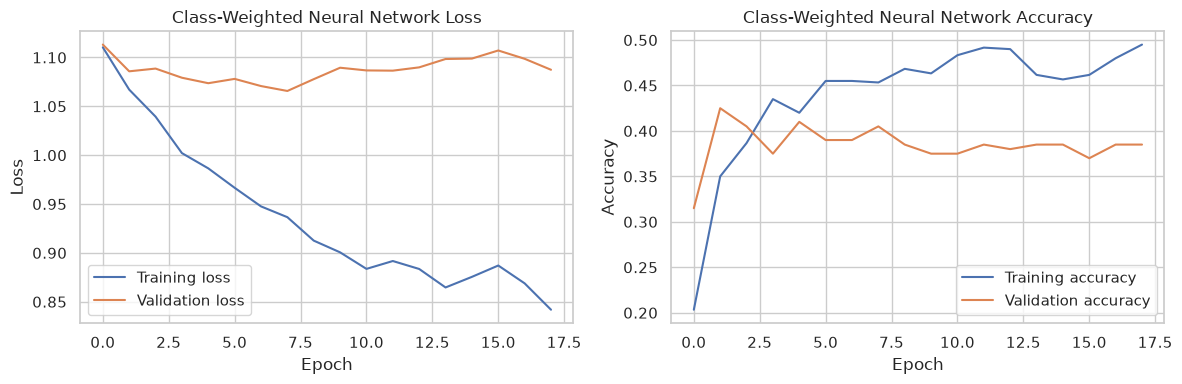

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(weighted_history.history["loss"], label="Training loss")
axes[0].plot(weighted_history.history["val_loss"], label="Validation loss")
axes[0].set_title("Class-Weighted Neural Network Loss")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Loss")
axes[0].legend()
axes[1].plot(weighted_history.history["accuracy"], label="Training accuracy")
axes[1].plot(weighted_history.history["val_accuracy"], label="Validation accuracy")
axes[1].set_title("Class-Weighted Neural Network Accuracy")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
fig.savefig(REPORTS_DIR / "weighted_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()

### Class-weighting conclusion

In the reviewed run, the unweighted Logistic Regression achieved the highest validation macro-F1 (0.439). Weighted models identified more Low-class examples but had lower macro-F1. We therefore retain unweighted Logistic Regression as the selected model for this project version. The tables above recalculate all metrics when this notebook is rerun; interpret the current output rather than assuming the same values on every environment.

## Section 10 — Baseline Test-Set Evaluation

The following reports reproduce the comparison of the three original baseline models on the held-out test set. The class-weighted variants are compared on validation data and are not included in this test comparison.

In [17]:
test_predictions = {
    "Dummy Classifier": dummy_model.predict(X_test_encoded),
    "Logistic Regression": logistic_model.predict(X_test_encoded),
    "Neural Network": decode_neural_predictions(neural_model, X_test_encoded),
}

test_results = pd.DataFrame([
    {"Model": name, **calculate_metrics(y_test, predictions)}
    for name, predictions in test_predictions.items()
]).sort_values("Macro-F1", ascending=False).reset_index(drop=True)
display(test_results.round(3))
test_results.to_csv(REPORTS_DIR / "model_comparison.csv", index=False)

,Model,Accuracy,Macro-F1
0,Logistic Regression,0.620,0.390
1,Neural Network,0.625,0.382
2,Dummy Classifier,0.575,0.243


### 10.1 Per-Class Precision, Recall, and F1

Overall accuracy can hide poor performance on a smaller class, so we also record precision, recall, F1-score, and support for every mastery category.

In [18]:
report_rows = []
for model_name, predictions in test_predictions.items():
    report = classification_report(
        y_test, predictions, labels=CLASS_NAMES, output_dict=True, zero_division=0
    )
    for class_name in CLASS_NAMES:
        report_rows.append({
            "Model": model_name,
            "Class": class_name,
            "Precision": report[class_name]["precision"],
            "Recall": report[class_name]["recall"],
            "F1-score": report[class_name]["f1-score"],
            "Support": int(report[class_name]["support"]),
        })
per_class_results = pd.DataFrame(report_rows)
display(per_class_results.round(3))
per_class_results.to_csv(REPORTS_DIR / "test_classification_report.csv", index=False)

,Model,Class,Precision,Recall,F1-score,Support
0,Dummy Classifier,Low,0.000,0.000,0.000,20
1,Dummy Classifier,Medium,0.575,1.000,0.730,115
2,Dummy Classifier,High,0.000,0.000,0.000,65
3,Logistic Regression,Low,0.000,0.000,0.000,20
4,Logistic Regression,Medium,0.618,0.887,0.729,115
5,Logistic Regression,High,0.629,0.338,0.440,65
6,Neural Network,Low,0.000,0.000,0.000,20
7,Neural Network,Medium,0.616,0.922,0.739,115
8,Neural Network,High,0.679,0.292,0.409,65


### 10.2 Confusion Matrices

Rows represent actual categories and columns represent predicted categories. Diagonal cells are correct predictions; off-diagonal cells are errors.

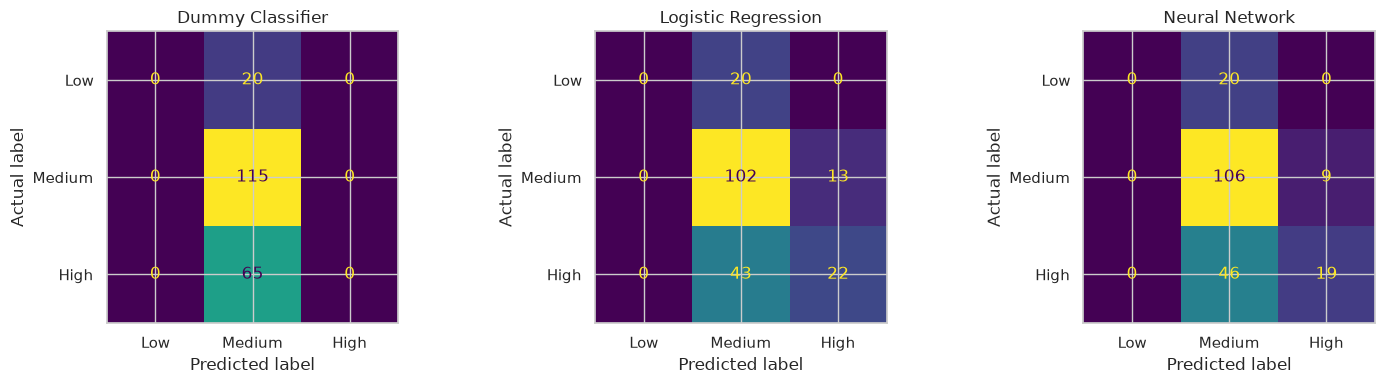

In [19]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, (model_name, predictions) in zip(axes, test_predictions.items()):
    matrix = confusion_matrix(y_test, predictions, labels=CLASS_NAMES)
    ConfusionMatrixDisplay(confusion_matrix=matrix, display_labels=CLASS_NAMES).plot(
        ax=ax, colorbar=False, values_format="d"
    )
    ax.set_title(model_name)
    ax.set_xlabel("Predicted label")
    ax.set_ylabel("Actual label")
plt.tight_layout()
fig.savefig(REPORTS_DIR / "confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 11 — Logistic Regression Coefficients

We examine the encoded coefficients associated with the High class as an introductory interpretability exercise. These are learned model associations, not causal effects. The features include demographic information, so the coefficients should be interpreted carefully and not used to make high-stakes decisions about individual students.

,Feature,Coefficient
9,parental level of education_high school,-0.523
13,lunch_free/reduced,-0.519
16,test preparation course_none,-0.497
12,parental level of education_some high school,-0.450
2,race/ethnicity_group A,-0.311
0,gender_female,0.208
5,race/ethnicity_group D,0.300
6,race/ethnicity_group E,0.367
8,parental level of education_bachelor's degree,0.369
15,test preparation course_completed,0.498


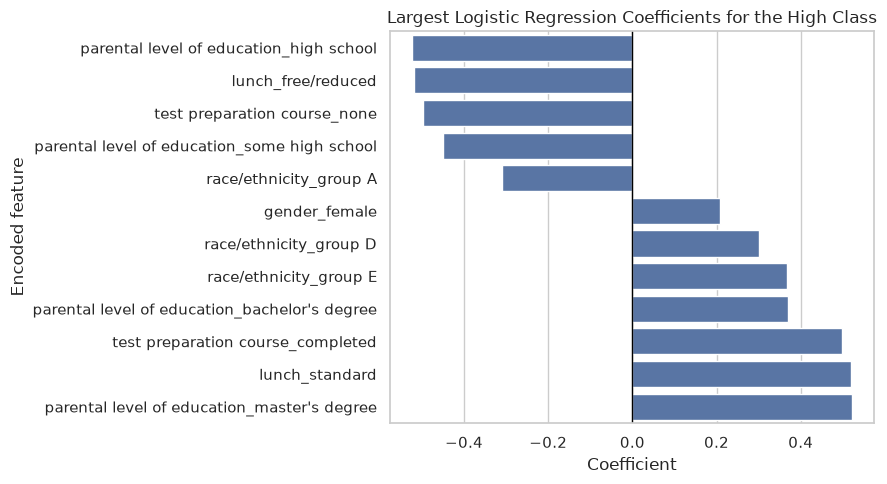

In [20]:
high_class_index = list(logistic_model.classes_).index("High")
high_coefficients = logistic_model.coef_[high_class_index]
coefficient_table = pd.DataFrame({"Feature": feature_names, "Coefficient": high_coefficients})
coefficient_table["Absolute coefficient"] = coefficient_table["Coefficient"].abs()
coefficient_table = coefficient_table.nlargest(12, "Absolute coefficient").sort_values("Coefficient")
display(coefficient_table.drop(columns="Absolute coefficient").round(3))

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=coefficient_table, x="Coefficient", y="Feature", ax=ax)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Largest Logistic Regression Coefficients for the High Class")
ax.set_xlabel("Coefficient")
ax.set_ylabel("Encoded feature")
fig.tight_layout()
fig.savefig(REPORTS_DIR / "logistic_regression_coefficients.png", dpi=150, bbox_inches="tight")
plt.show()

## Section 12 — Save Models, Preprocessing, and Reports

We save the fitted preprocessor and the models so later inference does not require retraining. The preprocessor must be the same fitted object used for training.

- `logistic_regression.joblib`: selected conventional classifier.
- `preprocessor.joblib`: fitted one-hot encoder pipeline.
- `student_mastery_model.keras`: original neural network.
- Additional files preserve the class-weighting experiment separately.

In [21]:
# Save the original models and the selected model's exact preprocessor.
NEURAL_MODEL_PATH = MODELS_DIR / "student_mastery_model.keras"
LOGISTIC_MODEL_PATH = MODELS_DIR / "logistic_regression.joblib"
PREPROCESSOR_PATH = MODELS_DIR / "preprocessor.joblib"
WEIGHTED_LOGISTIC_PATH = MODELS_DIR / "logistic_regression_class_weighted.joblib"
WEIGHTED_NEURAL_PATH = MODELS_DIR / "student_mastery_model_class_weighted.keras"

neural_model.save(NEURAL_MODEL_PATH)
joblib.dump(logistic_model, LOGISTIC_MODEL_PATH)
joblib.dump(preprocessor, PREPROCESSOR_PATH)
joblib.dump(weighted_logistic_model, WEIGHTED_LOGISTIC_PATH)
weighted_neural_model.save(WEIGHTED_NEURAL_PATH)

artifact_paths = [
    LOGISTIC_MODEL_PATH,
    PREPROCESSOR_PATH,
    NEURAL_MODEL_PATH,
    WEIGHTED_LOGISTIC_PATH,
    WEIGHTED_NEURAL_PATH,
    REPORTS_DIR / "model_comparison.csv",
    REPORTS_DIR / "test_classification_report.csv",
    REPORTS_DIR / "training_curves.png",
    REPORTS_DIR / "weighted_training_curves.png",
    REPORTS_DIR / "confusion_matrices.png",
    REPORTS_DIR / "logistic_regression_coefficients.png",
    REPORTS_DIR / "validation_class_weighting_comparison.csv",
]
artifact_status = pd.DataFrame({
    "Artifact": [str(path.relative_to(PROJECT_ROOT)) for path in artifact_paths],
    "Exists": [path.exists() for path in artifact_paths],
    "Size (bytes)": [path.stat().st_size if path.exists() else None for path in artifact_paths],
})
display(artifact_status)
if not artifact_status["Exists"].all():
    raise RuntimeError("One or more expected artifacts were not created. Check the table above.")
print("Models and reports saved successfully.")

,Artifact,Exists,Size (bytes)
0,models/logistic_regression.joblib,True,1439
1,models/preprocessor.joblib,True,2897
2,models/student_mastery_model.keras,True,67797
3,models/logistic_regression_class_weighted.joblib,True,1455
4,models/student_mastery_model_class_weighted.keras,True,67807
5,reports/model_comparison.csv,True,152
6,reports/test_classification_report.csv,True,572
7,reports/training_curves.png,True,116158
8,reports/weighted_training_curves.png,True,120268
9,reports/confusion_matrices.png,True,82696


Models and reports saved successfully.


## Section 13 — Pre-Exam Prediction

This section loads the saved, unweighted Logistic Regression model and the fitted preprocessor. It accepts five categorical features, predicts a mastery category, displays class probabilities, and maps the prediction to a practice recommendation.

These recommendations are simple rules attached to the predicted category; they are not produced by a separate trained recommender.

In [22]:
# Reload from disk to verify that the saved artifacts can be used for inference.
inference_preprocessor = joblib.load(PREPROCESSOR_PATH)
inference_model = joblib.load(LOGISTIC_MODEL_PATH)

encoder = inference_preprocessor.named_transformers_["categorical"]
allowed_categories = {
    feature: [str(value) for value in categories]
    for feature, categories in zip(CATEGORICAL_FEATURES, encoder.categories_)
}

PRACTICE_RECOMMENDATIONS = {
    "Low": "Start with foundational practice. Review core concepts and work through guided, easier questions before progressing.",
    "Medium": "Practise core concepts with a mix of easy and moderate questions. Review mistakes and gradually increase difficulty.",
    "High": "Practise challenging application and multi-step questions, while using mixed practice to maintain existing skills.",
}

print("Loaded saved Logistic Regression model and preprocessor.")
print("Model classes:", list(inference_model.classes_))

Loaded saved Logistic Regression model and preprocessor.
Model classes: ['High', 'Low', 'Medium']


### 13.1 Define a Reusable Prediction Function

The function validates the five required inputs, transforms them with the saved preprocessor, and returns the predicted category, class probabilities, and matching practice recommendation.

In [23]:
def predict_mastery(student_profile):
    """Predict mastery from the five categorical inputs and return probabilities."""
    missing_features = [feature for feature in CATEGORICAL_FEATURES if feature not in student_profile]
    extra_features = [feature for feature in student_profile if feature not in CATEGORICAL_FEATURES]
    if missing_features:
        raise ValueError(f"Missing required features: {missing_features}")
    if extra_features:
        raise ValueError(f"Unexpected features: {extra_features}")

    for feature in CATEGORICAL_FEATURES:
        if student_profile[feature] not in allowed_categories[feature]:
            raise ValueError(
                f"Invalid value for '{feature}': {student_profile[feature]!r}. "
                f"Choose one of: {allowed_categories[feature]}"
            )

    input_df = pd.DataFrame(
        [{feature: student_profile[feature] for feature in CATEGORICAL_FEATURES}],
        columns=CATEGORICAL_FEATURES,
    )
    encoded_input = inference_preprocessor.transform(input_df)
    predicted_category = str(inference_model.predict(encoded_input)[0])
    probability_values = inference_model.predict_proba(encoded_input)[0]
    probabilities = pd.DataFrame({
        "Mastery Level": inference_model.classes_,
        "Probability": probability_values,
    }).sort_values("Probability", ascending=False).reset_index(drop=True)

    return {
        "input": input_df,
        "predicted_mastery": predicted_category,
        "probabilities": probabilities,
        "recommendation": PRACTICE_RECOMMENDATIONS[predicted_category],
    }

### 13.2 Run an Example Pre-Exam Prediction

The values below are an example only. They must match categories present in the fitted encoder.

In [24]:
sample_student = {
    "gender": "female",
    "race/ethnicity": "group C",
    "parental level of education": "bachelor's degree",
    "lunch": "standard",
    "test preparation course": "completed",
}
sample_result = predict_mastery(sample_student)
display(sample_result["input"])
print("Predicted mastery level:", sample_result["predicted_mastery"])
print("\nClass probabilities:")
display(sample_result["probabilities"].style.format({"Probability": "{:.1%}"}))
print("\nSuggested practice:")
print(sample_result["recommendation"])

,gender,race/ethnicity,parental level of education,lunch,test preparation course
0,female,group C,bachelor's degree,standard,completed


Predicted mastery level: High

Class probabilities:


,Mastery Level,Probability
0,High,66.8%
1,Medium,32.4%
2,Low,0.8%



Suggested practice:
Practise challenging application and multi-step questions, while using mixed practice to maintain existing skills.


## Section 14 — Post-Exam Recommendation

This mode uses the student's actual Mathematics, Reading, and Writing scores. It identifies the lowest-scoring subject and suggests foundational review and practice. This is a rule-based function, not a second trained machine-learning model.

In [25]:
def recommend_after_exam(math_score, reading_score, writing_score):
    """Recommend a subject to review using actual scores from 0 to 100."""
    scores = {
        "Mathematics": math_score,
        "Reading": reading_score,
        "Writing": writing_score,
    }
    for subject, score in scores.items():
        if not isinstance(score, (int, float, np.integer, np.floating)):
            raise TypeError(f"{subject} score must be numeric.")
        if not np.isfinite(score) or not 0 <= score <= 100:
            raise ValueError(f"{subject} score must be between 0 and 100.")

    lowest_score = min(scores.values())
    weakest_subjects = [subject for subject, score in scores.items() if score == lowest_score]
    if len(weakest_subjects) == 1:
        recommendation = (
            f"Prioritize {weakest_subjects[0]}. Review foundational concepts, work through "
            "guided examples, and practise related questions."
        )
    else:
        recommendation = (
            f"Your lowest scores are tied in {', '.join(weakest_subjects)}. Review the core concepts "
            "in these subjects and practise related questions."
        )
    return {
        "scores": scores,
        "lowest_score": lowest_score,
        "weakest_subjects": weakest_subjects,
        "recommendation": recommendation,
    }

### 14.1 Run an Example Post-Exam Recommendation

In [26]:
post_exam_result = recommend_after_exam(math_score=55, reading_score=78, writing_score=72)
print("Exam scores:")
display(pd.DataFrame(list(post_exam_result["scores"].items()), columns=["Subject", "Score"]))
print("Lowest score:", post_exam_result["lowest_score"])
print("Subject(s) to review:", ", ".join(post_exam_result["weakest_subjects"]))
print("Recommendation:", post_exam_result["recommendation"])

Exam scores:


,Subject,Score
0,Mathematics,55
1,Reading,78
2,Writing,72


Lowest score: 55
Subject(s) to review: Mathematics
Recommendation: Prioritize Mathematics. Review foundational concepts, work through guided examples, and practise related questions.


## Section 15 — Final Verification

These assertions check that the saved model can make a valid prediction, its class probabilities sum to approximately 1, and the post-exam rule identifies Mathematics as the weakest subject in the example.

In [27]:
probability_total = sample_result["probabilities"]["Probability"].sum()
assert sample_result["predicted_mastery"] in CLASS_NAMES
assert np.isclose(probability_total, 1.0, atol=1e-6)
assert post_exam_result["weakest_subjects"] == ["Mathematics"]
assert all(path.exists() for path in artifact_paths)

print("All inference, recommendation, and artifact checks passed.")
print(f"Probability total: {probability_total:.6f}")
print(f"Saved artifacts verified: {len(artifact_paths)}")

All inference, recommendation, and artifact checks passed.
Probability total: 1.000000
Saved artifacts verified: 12


## Section 16 — Results, Limitations, and Viva Notes

### What this project implements

- Data validation and exploratory analysis.
- An engineered three-category mastery target.
- A stratified train/validation/test split and one-hot encoding.
- Dummy Classifier, Logistic Regression, and a small neural network.
- A class-weighting experiment compared on validation data.
- Evaluation with accuracy, macro-F1, per-class metrics, and confusion matrices.
- Saved model artifacts and two recommendation modes.

### How to interpret the results

In the reviewed run, the baseline test results were:

| Model | Accuracy | Macro-F1 |
|---|---:|---:|
| Dummy Classifier | 57.5% | 0.243 |
| Logistic Regression | 62.0% | 0.390 |
| Neural Network | 62.5% | 0.382 |

The original Logistic Regression achieved the highest validation macro-F1 in the reviewed class-weighting experiment (0.439), so it was selected for the current recommendation workflow. The notebook recalculates its metrics when rerun; refer to the actual tables above if results vary.

### Limitations

- The target labels are engineered using thresholds, not supplied as official labels by the dataset.
- The model uses only five categorical profile features, so predictive performance is limited.
- In the reviewed test results, the selected baseline model did not identify Low-mastery examples (0% Low-class recall). Recommendations should not be treated as authoritative educational assessments.
- Demographic features can encode sensitive associations. The analysis is observational and does not establish causation.
- The dataset has no question-level or topic-level information, so the project cannot diagnose individual question difficulty or topic mastery.
- The post-exam recommendation is a transparent rule based only on subject scores.

### Likely viva questions

**Q1. Why are exam scores excluded from the model inputs?**  
They define the target label, so using them as inputs would cause target leakage.

**Q2. Why compare against a Dummy Classifier?**  
It establishes a simple reference point; a more complex model should provide value beyond a majority-class prediction.

**Q3. Why use macro-F1 alongside accuracy?**  
Macro-F1 weights the three classes equally and helps expose poor performance on a minority class.

**Q4. Why use the saved preprocessor during inference?**  
It ensures new inputs are encoded with the same categories and feature layout learned during training.

**Q5. Does this project predict the difficulty of individual questions?**  
No. The dataset has no question-level labels; the project predicts an engineered student mastery category and maps it to a broad practice recommendation.